# Fixed-width window FFD — Z reference comparison (expanding vs rolling)

Same data, FFD and plot range as `ffd-z-plot.ipynb`. Only the Z reference changes.

| Item | Setting |
|---|---|
| Method | Fixed-width window FFD on `log(close)`, daily |
| τ / d / FFD window | 1e-4 / 0.25 / 445 bars |
| Train | 2021-01-01 → 2023-12-31 |
| Plot range | data start → **2022-12-31** (`PLOT_END`) |
| Z anchor | each asset's first FFD value (warm-up end): BTC/ETH 2020-03-20, QQQ 2020-10-06, XAUUSD 2020-09-21 |
| Z burn-in | `Z_MIN` = 60 FFD bars before the first Z, for every reference |

`Z_t = (FFD_t − μ_t) / σ_t` (ddof = 0). The references differ only in which FFD values feed μ_t and σ_t:

| Name | μ/σ window on day t | Window in bars |
|---|---|---|
| **expanding** | anchor → t | grows every bar |
| **ffd 445** | last 445 bars (= FFD window) | 445 |
| **100 bars** | last 100 bars | 100 |
| **200 bars** | last 200 bars | 200 |
| **1 year** | last 365 calendar days | crypto ≈ 365, QQQ/XAUUSD ≈ 252 |
| **2 years** | last 730 calendar days | crypto ≈ 730, QQQ/XAUUSD ≈ 504 |

- Every rolling window holds everything since the anchor until it fills (it behaves like expanding before that). The table below lists when each one fills.
- All references are causal: Z_t uses no data after t.
- Five comparison sets follow. Each figure shows Z only, one panel per asset.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

DATA = Path('../../data')
ASSETS = ['BTC', 'ETH', 'QQQ', 'XAUUSD']
TAU, D = 1e-4, 0.25
TRAIN = ('2021-01-01', '2023-12-31')
Z_MIN = 60
PLOT_END = '2022-12-31'

def ffd_weights(d, tau=TAU):
    w = [1.0]
    while True:
        k = len(w)
        nxt = -w[-1] * (d - k + 1) / k
        if abs(nxt) < tau:
            return np.asarray(w)
        w.append(nxt)

def ffd(log_close, d=D, tau=TAU):
    w = ffd_weights(d, tau)
    y = np.full(len(log_close), np.nan)
    y[len(w) - 1:] = np.convolve(log_close.values, w, mode='valid')
    return pd.Series(y, index=log_close.index)

def load(sym):
    df = pd.read_parquet(DATA / sym / f'{sym}-sorted-1d.parquet')
    ts = pd.to_datetime(df['timestamp'])
    ts = ts.dt.tz_convert(None) if ts.dt.tz is not None else ts
    assert ts.is_monotonic_increasing and ts.is_unique
    return df.set_axis(ts)['close']

W = len(ffd_weights(D))
# window: None = expanding, int = bars, str = calendar days
REFS = {'expanding': None, 'ffd 445': W, '100 bars': 100, '200 bars': 200, '1 year': '365D', '2 years': '730D'}
COLORS = {'expanding': '0.45', 'ffd 445': 'tab:blue', '100 bars': 'tab:orange', '200 bars': 'tab:green',
          '1 year': 'tab:red', '2 years': 'tab:purple'}
W

445

In [2]:
def z_ref(fa, win):
    r = fa.expanding(Z_MIN) if win is None else fa.rolling(win, min_periods=Z_MIN)
    return (fa - r.mean()) / r.std(ddof=0)

def full_from(fa, win):
    if win is None:
        return None
    if isinstance(win, int):
        return fa.index[win - 1] if len(fa) >= win else None
    d = fa.index[0] + pd.Timedelta(win)
    return d if d <= fa.index[-1] else None

Z, FA, ANCHOR = {}, {}, {}
for s in ASSETS:
    f = ffd(np.log(load(s).loc[:PLOT_END]))
    fa = f.loc[f.first_valid_index():]
    FA[s], ANCHOR[s] = fa, fa.index[0]
    Z[s] = pd.DataFrame({k: z_ref(fa, w) for k, w in REFS.items()})

def bars_in(s, win):
    # average bars per calendar window for this asset (for labels)
    per_year = FA[s].groupby(FA[s].index.year).size().loc['2021':'2022'].mean() if len(FA[s]) else np.nan
    return int(round(per_year * pd.Timedelta(win).days / 365))

def label(s, k):
    w = REFS[k]
    if isinstance(w, str):
        return f'{k} (≈{bars_in(s, w)} bars)'
    return k

pd.DataFrame({s: {'anchor': ANCHOR[s].date(),
                  **{f'{k} full from': (full_from(FA[s], w).date() if full_from(FA[s], w) is not None else 'not in range')
                     for k, w in REFS.items() if w is not None},
                  **{f'{k} ≈ bars': bars_in(s, REFS[k]) for k in ['1 year', '2 years']}} for s in ASSETS}).T

,anchor,ffd 445 full from,100 bars full from,200 bars full from,1 year full from,2 years full from,1 year ≈ bars,2 years ≈ bars
BTC,2020-03-20,2021-06-07,2020-06-27,2020-10-05,2021-03-20,2022-03-20,365,730
ETH,2020-03-20,2021-06-07,2020-06-27,2020-10-05,2021-03-20,2022-03-20,365,730
QQQ,2020-10-06,2022-07-13,2021-03-01,2021-07-22,2021-10-06,2022-10-06,252,503
XAUUSD,2020-09-21,2022-06-10,2021-02-09,2021-06-30,2021-09-21,2022-09-21,258,516


In [3]:
def plot_set(keys, title):
    fig, axes = plt.subplots(len(ASSETS), 1, figsize=(12, 2.4 * len(ASSETS)), sharex=True)
    for ax, s in zip(axes, ASSETS):
        for k in keys:
            ax.plot(Z[s].index, Z[s][k], color=COLORS[k], lw=1.2 if k == 'expanding' else 1, label=label(s, k))
            ff = full_from(FA[s], REFS[k])
            if ff is not None:
                ax.axvline(ff, color=COLORS[k], lw=0.8, ls=':')
        for lvl, ls in [(0, '-'), (2, '--'), (-2, '--')]:
            ax.axhline(lvl, color='0.6', lw=0.6, ls=ls)
        ax.axvspan(pd.Timestamp(TRAIN[0]), pd.Timestamp(PLOT_END), color='tab:orange', alpha=0.06)
        ax.set_ylabel(s); ax.legend(loc='upper right', fontsize=8, ncol=len(keys))
    axes[0].set_title(f'{title} — dotted = window full, shaded = train (to {PLOT_END})', loc='left', fontsize=10)
    plt.tight_layout(); plt.show()

def summary(keys):
    t = pd.concat({s: Z[s][keys].loc['2021':].groupby(Z[s].loc['2021':].index.year).mean() for s in ASSETS})
    t.columns = [f'{k} mean Z' for k in keys]
    return t.round(2)

## Set 1 — expanding vs ffd 445

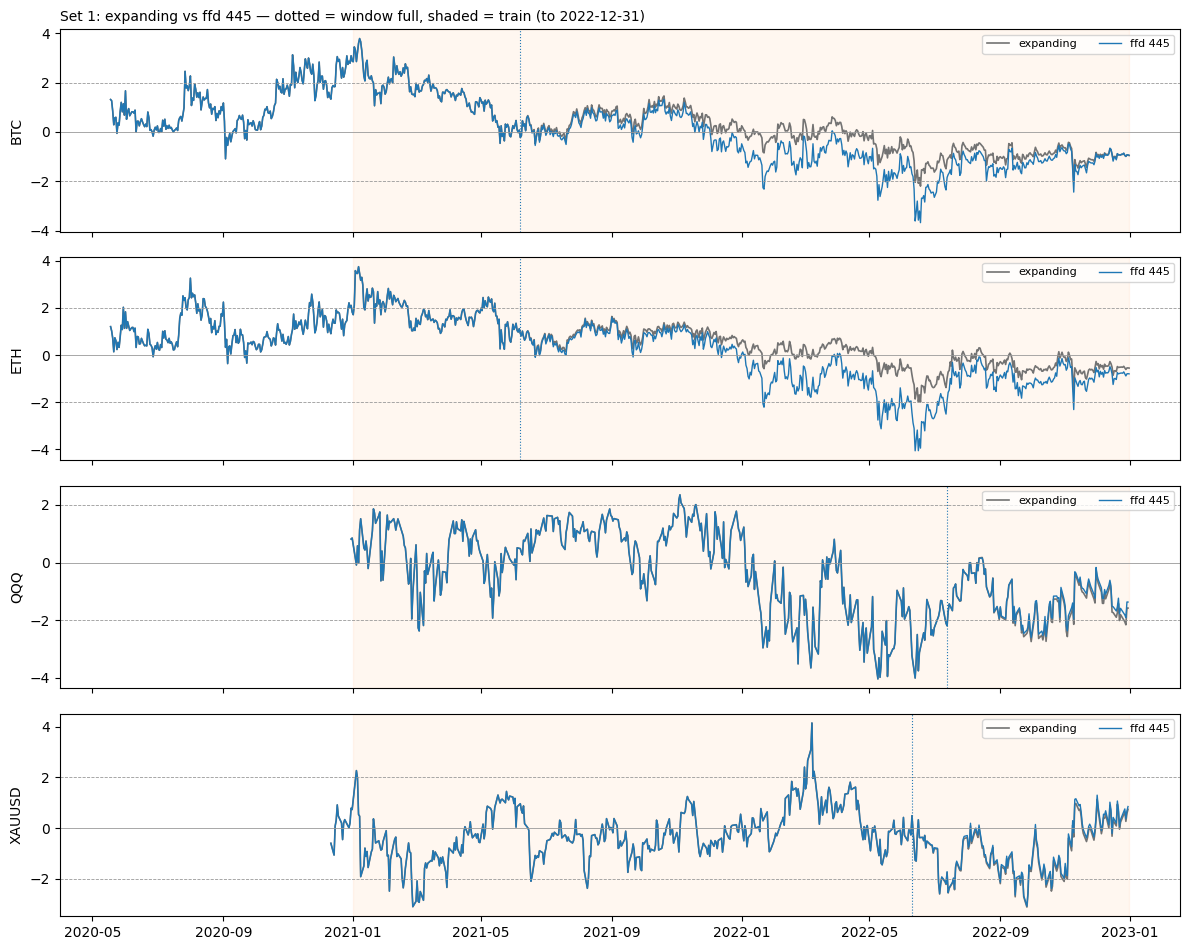

expanding mean Z  ffd 445 mean Z
       timestamp                                  
BTC    2021                   0.98            0.83
       2022                  -0.63           -1.27
ETH    2021                   1.28            1.18
       2022                  -0.29           -1.18
QQQ    2021                   0.63            0.63
       2022                  -1.58           -1.53
XAUUSD 2021                  -0.49           -0.49
       2022                  -0.32           -0.27

In [4]:
keys = ['expanding', 'ffd 445']
plot_set(keys, 'Set 1: expanding vs ffd 445')
summary(keys)

## Set 2 — expanding vs 1 year and 2 years

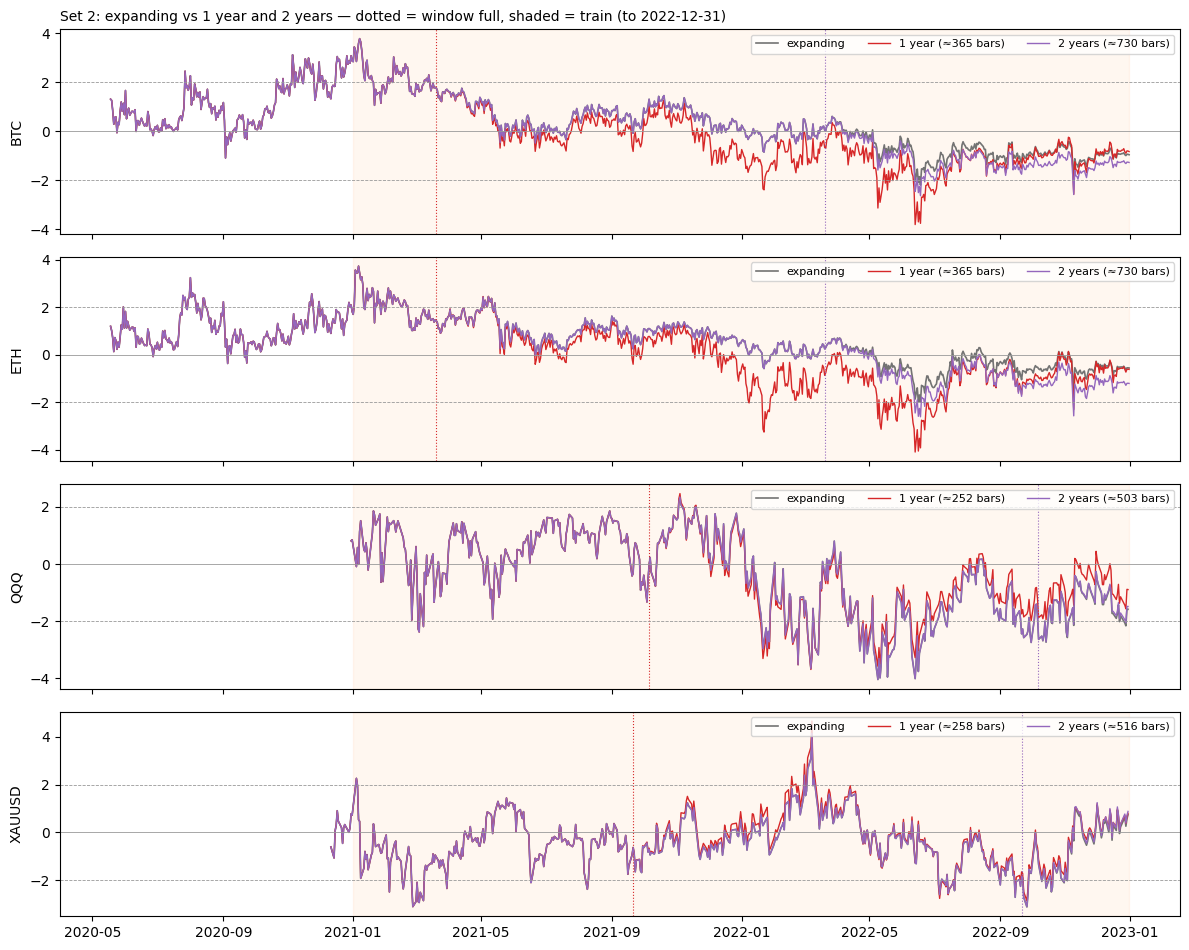

expanding mean Z  1 year mean Z  2 years mean Z
       timestamp                                                 
BTC    2021                   0.98           0.66            0.98
       2022                  -0.63          -1.19           -0.89
ETH    2021                   1.28           1.04            1.28
       2022                  -0.29          -1.17           -0.63
QQQ    2021                   0.63           0.62            0.63
       2022                  -1.58          -1.26           -1.57
XAUUSD 2021                  -0.49          -0.45           -0.49
       2022                  -0.32          -0.16           -0.30

In [5]:
keys = ['expanding', '1 year', '2 years']
plot_set(keys, 'Set 2: expanding vs 1 year and 2 years')
summary(keys)

## Set 3 — expanding vs 100 bars and 200 bars

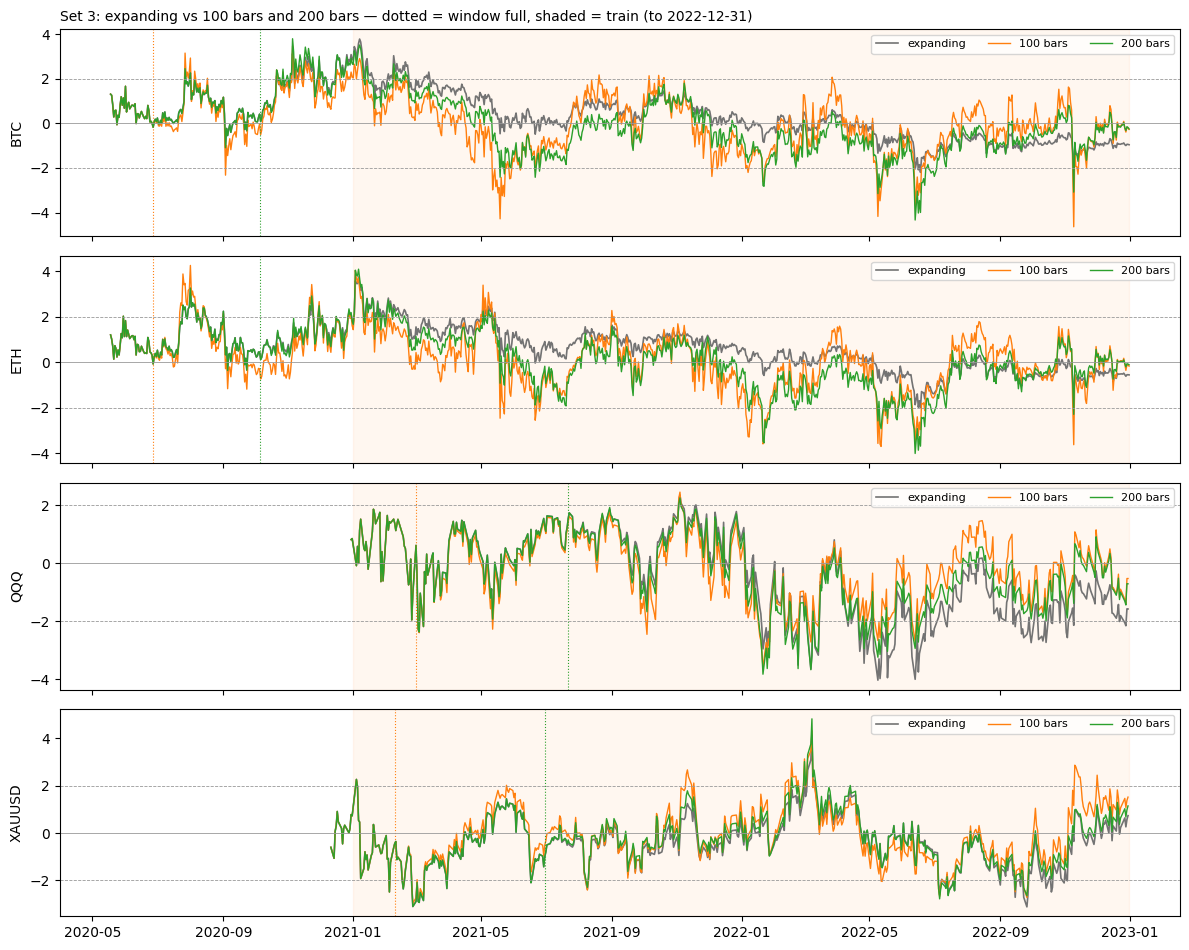

expanding mean Z  100 bars mean Z  200 bars mean Z
       timestamp                                                    
BTC    2021                   0.98             0.09             0.26
       2022                  -0.63            -0.50            -0.92
ETH    2021                   1.28             0.37             0.61
       2022                  -0.29            -0.50            -0.82
QQQ    2021                   0.63             0.38             0.57
       2022                  -1.58            -0.71            -1.14
XAUUSD 2021                  -0.49            -0.20            -0.38
       2022                  -0.32            -0.01            -0.15

In [6]:
keys = ['expanding', '100 bars', '200 bars']
plot_set(keys, 'Set 3: expanding vs 100 bars and 200 bars')
summary(keys)

## Set 4 — ffd 445 vs 100 bars and 200 bars

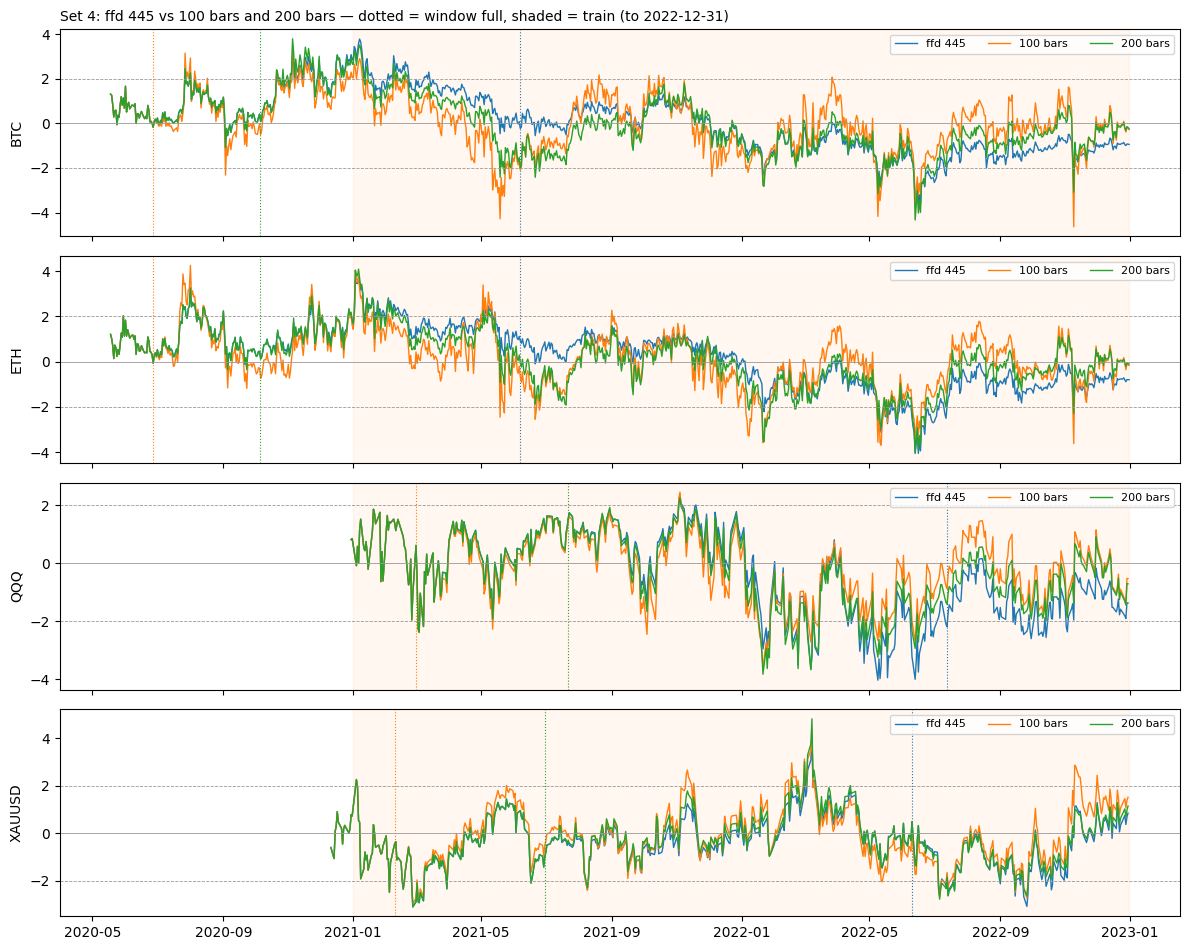

ffd 445 mean Z  100 bars mean Z  200 bars mean Z
       timestamp                                                  
BTC    2021                 0.83             0.09             0.26
       2022                -1.27            -0.50            -0.92
ETH    2021                 1.18             0.37             0.61
       2022                -1.18            -0.50            -0.82
QQQ    2021                 0.63             0.38             0.57
       2022                -1.53            -0.71            -1.14
XAUUSD 2021                -0.49            -0.20            -0.38
       2022                -0.27            -0.01            -0.15

In [7]:
keys = ['ffd 445', '100 bars', '200 bars']
plot_set(keys, 'Set 4: ffd 445 vs 100 bars and 200 bars')
summary(keys)

## Set 5 — 100 bars and 200 bars vs 1 year and 2 years

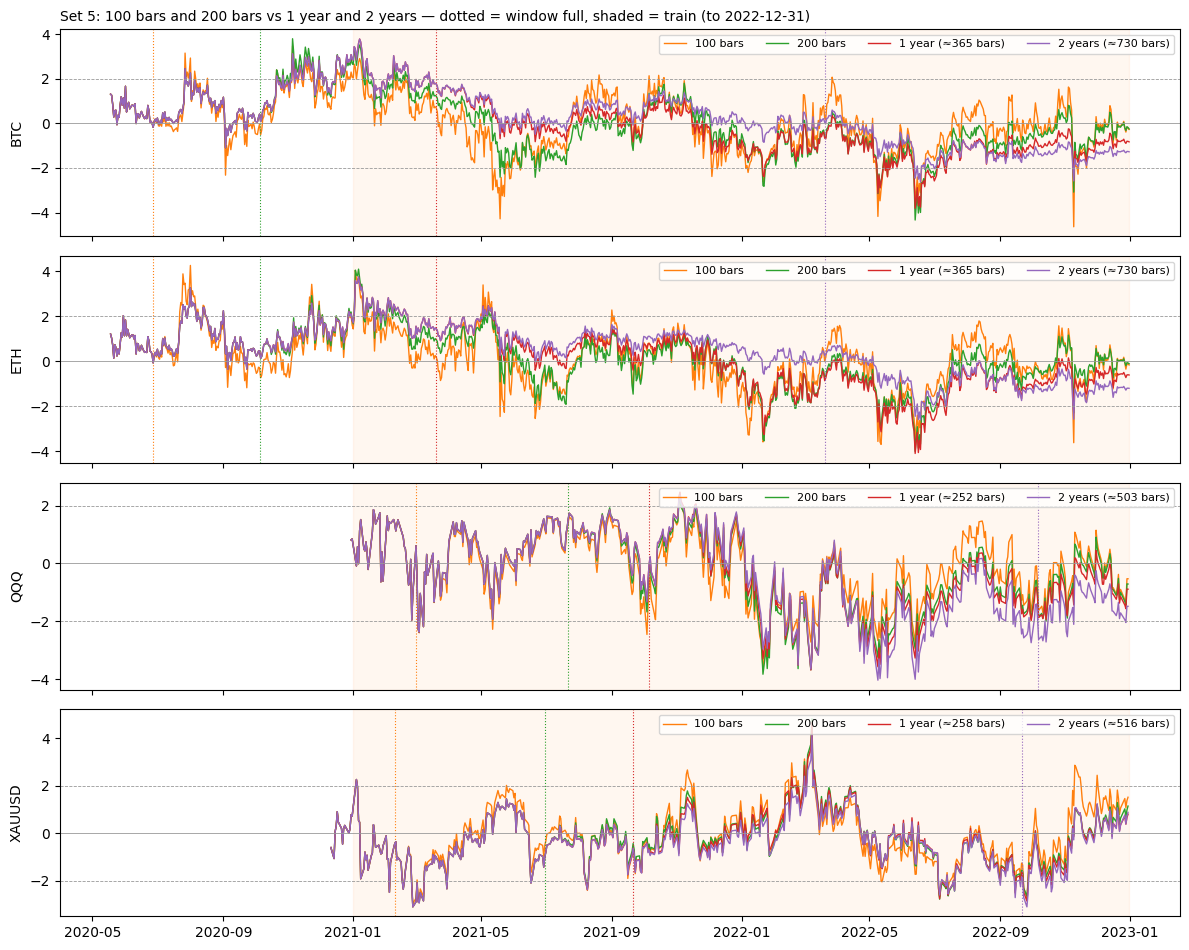

100 bars mean Z  200 bars mean Z  1 year mean Z  \
       timestamp                                                    
BTC    2021                  0.09             0.26           0.66   
       2022                 -0.50            -0.92          -1.19   
ETH    2021                  0.37             0.61           1.04   
       2022                 -0.50            -0.82          -1.17   
QQQ    2021                  0.38             0.57           0.62   
       2022                 -0.71            -1.14          -1.26   
XAUUSD 2021                 -0.20            -0.38          -0.45   
       2022                 -0.01            -0.15          -0.16   

                  2 years mean Z  
       timestamp                  
BTC    2021                 0.98  
       2022                -0.89  
ETH    2021                 1.28  
       2022                -0.63  
QQQ    2021                 0.63  
       2022                -1.57  
XAUUSD 2021                -0.49  
       2022                -0.30

In [8]:
keys = ['100 bars', '200 bars', '1 year', '2 years']
plot_set(keys, 'Set 5: 100 bars and 200 bars vs 1 year and 2 years')
summary(keys)

Notes
- Shorter windows re-centre faster after a level shift, and also call a trend "normal" sooner.
- Before a window fills, it equals expanding. Compare windows only after their dotted line.
- 1 year / 2 years count calendar days, so they hold fewer bars for QQQ/XAUUSD (≈252 / ≈504) than for crypto (≈365 / ≈730). 100 / 200 / 445 bars count bars, so they cover a longer calendar span for QQQ/XAUUSD.
- Choose N on train (2021–2023) or by Stage B, not by how 2024+ looks.
- Stationarity ≠ mean reversion of price. Z alone is not a buy/sell signal.

## Conclusion — Z reference for the feature (decided 2026-10-31)

**Use either expanding Z or rolling Z over 445 bars (= FFD window). Both go into Stage B. 100 / 200 bars and 1y / 2y are dropped.**

| Reference | Why it stays | Weak point |
|---|---|---|
| **Expanding** (anchor → t) | No free parameter; stable; Z means "vs everything since the anchor" | Re-centres slowly after a lasting level shift; early Z is noisy |
| **Rolling 445 bars** (= FFD window) | No free parameter (follows d, τ); re-centres after a level shift; Z judges FFD over the same span its memory covers | 445 bars ≈ 1.2y crypto vs ≈ 1.8y QQQ/XAUUSD; fills late (crypto 2021-06-07, QQQ 2022-07-13, XAUUSD 2022-06-10) |

Why the others were dropped:
- **100 / 200 bars** judge a 445-bar-memory feature against only 3–9 months. That makes Z a short-term oscillator, closer to RSI or momentum, the baselines it must beat. And 100/200 have no basis beyond the plots.
- **1y / 2y** add a free parameter with no advantage over 445 bars.

Expanding anchor reset: only on a setup change (new d, data source or timeframe). Never in reaction to Z drifting.

FFD itself is the same on every asset: one 445-bar window (τ = 1e-4, d = 0.25).